<a href="https://colab.research.google.com/github/Ayatamer04/Machine-learning-course/blob/master/regression_lab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning - Lab Assignment
## Linear Regression, Ridge and Lasso

Name: ______Tamer aya____________________    Group: _____1_____    Date: _____10_11_2026___

Use Python 3 and Jupyter Notebook. Required packages: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. If needed, install them with `pip install numpy pandas matplotlib scikit-learn`.

Work through the tasks in order. Create the dataset in Task 1; no external file is needed.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Task 1. Generate the dataset

Create a DataFrame named `df` with 500 synthetic salary records:

- Set the NumPy random seed to **42**.
- Generate 500 integers for `YearsOfExperience`, between **2 and 20 inclusive**, with `np.random.randint(2, 21, size=500)`.
- Set `intercept = 60000` and `slope = (200000 - 60000) / (20 - 2)`.
- Generate 500 noise values from a normal distribution using `np.random.normal(0, 10000, size=500)`.
- Compute `Salary = intercept + slope * YearsOfExperience + noise`.
- Use pandas to create `df` with exactly two columns: `YearsOfExperience` and `Salary`. Display its first five rows and check that its shape is `(500, 2)`.

Generate the experience values **before** generating the noise. Do not load a dataset from a file.

In [1]:
import numpy as np
import pandas as pd

np.random.seed(42)

years_of_experience = np.random.randint(2, 21, size=500)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)


noise = np.random.normal(0, 10000, size=500)

salary = intercept + slope * years_of_experience + noise


df = pd.Data_Frame({
    "YearsOfExperience": years_of_experience,
    "Salary": salary
})
print(df.head())

print("Shape:", df.shape)
assert df.shape == (500, 2), "Unexpected shape!"

   YearsOfExperience         Salary
0                  8  115037.780010
1                 16  182309.972927
2                 12  156442.408989
3                  9  144753.562169
4                  8  130798.818454
Shape: (500, 2)


### Task 2. Explore the dataset

Display the dataset shape, summary statistics and number of missing values in each column. Calculate the correlation between `YearsOfExperience` and `Salary`.

In [2]:
import numpy as np
import pandas as pd

np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})

print("Dataset shape:", df.shape)

print("\nSummary statistics:")
print(df.describe())

print("\nMissing values per column:")
print(df.isnull().sum())

correlation = df["YearsOfExperience"].corr(df["Salary"])
print(f"\nPearson correlation (YearsOfExperience, Salary): {correlation:.4f}")

Dataset shape: (500, 2)

Summary statistics:
       YearsOfExperience         Salary
count         500.000000     500.000000
mean           10.616000  142570.011096
std             5.662922   44935.263058
min             2.000000   54881.134555
25%             5.750000  104426.300731
50%            10.000000  139865.032545
75%            16.000000  182341.125962
max            20.000000  241879.376204

Missing values per column:
YearsOfExperience    0
Salary               0
dtype: int64

Pearson correlation (YearsOfExperience, Salary): 0.9751


### Task 3. Plot the data

Draw a scatter plot with `YearsOfExperience` on the x-axis and `Salary` on the y-axis. Add axis labels and a title.

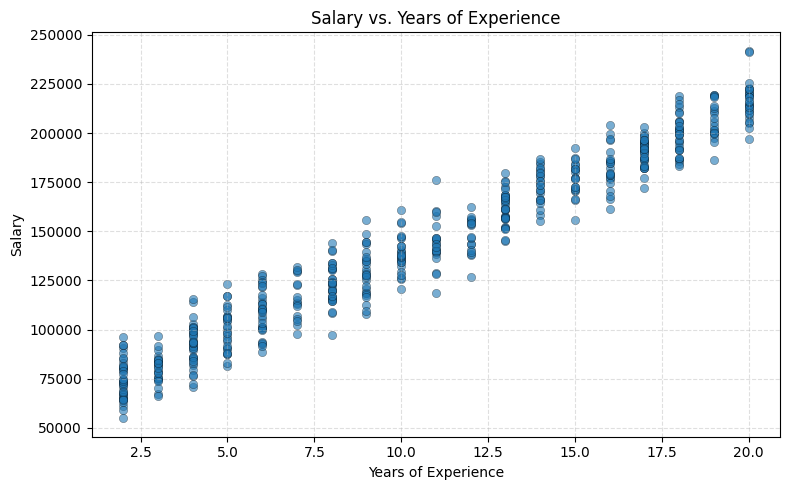

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})


plt.figure(figsize=(8, 5))
plt.scatter(df["YearsOfExperience"], df["Salary"], alpha=0.6, edgecolor="k", linewidth=0.3)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs. Years of Experience")

plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Task 4. Split the dataset

Set `X` to the `YearsOfExperience` column as a two-dimensional DataFrame and `y` to `Salary`. Use `train_test_split` with `test_size=0.20` and `random_state=42`. Display the number of training and test records.

In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})

X = df[["YearsOfExperience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of training records:", len(X_train))
print("Number of test records:", len(X_test))

X shape: (500, 1)
y shape: (500,)
Number of training records: 400
Number of test records: 100


### Task 5. Train linear regression

Fit a `LinearRegression` model on the training data. Display the slope, intercept, training R2 and test R2.

In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})

X = df[["YearsOfExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)


model = LinearRegression()
model.fit(X_train, y_train)


print(f"Slope (coefficient): {model.coef_[0]:.4f}")
print(f"Intercept:           {model.intercept_:.4f}")
print(f"Training R2:         {model.score(X_train, y_train):.4f}")
print(f"Test R2:             {model.score(X_test, y_test):.4f}")

Slope (coefficient): 7696.6129
Intercept:           60961.3409
Training R2:         0.9488
Test R2:             0.9574


### Task 6. Evaluate linear regression

Predict salary for the test set. Calculate MAE, MSE, RMSE and R2. Display the first five actual and predicted salaries in a table.

In [8]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})


X = df[["YearsOfExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE : {mae:.2f}")
print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2  : {r2:.4f}")

results = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
})
print("\nFirst five actual vs. predicted salaries:")
print(results.head())

MAE : 7905.11
MSE : 93933277.38
RMSE: 9691.92
R2  : 0.9574

First five actual vs. predicted salaries:
   Actual Salary  Predicted Salary
0  123631.230350     107141.018419
1  139775.630647     122534.244265
2   93184.812446     107141.018419
3  166740.803478     161017.308880
4  174587.183981     184107.147649


### Task 7. Compare with a baseline

Use the mean of `y_train` as the predicted salary for every test record. Compute baseline MAE and RMSE and compare them with linear regression.

In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})


X = df[["YearsOfExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
model = LinearRegression().fit(X_train, y_train)


y_pred_lr = model.predict(X_test)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

baseline_value = y_train.mean()
y_pred_base = np.full(shape=len(y_test), fill_value=baseline_value)
mae_base = mean_absolute_error(y_test, y_pred_base)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))

comparison = pd.DataFrame({
    "MAE":  [mae_base, mae_lr],
    "RMSE": [rmse_base, rmse_lr]
}, index=["Baseline (mean of y_train)", "Linear Regression"])

print(f"Baseline prediction (mean of y_train): {baseline_value:.2f}\n")
print(comparison.round(2))


print(f"\nMAE improvement : {(mae_base - mae_lr) / mae_base * 100:.1f}%")
print(f"RMSE improvement: {(rmse_base - rmse_lr) / rmse_base * 100:.1f}%")

Baseline prediction (mean of y_train): 142353.02

                                 MAE      RMSE
Baseline (mean of y_train)  40444.96  46953.77
Linear Regression            7905.11   9691.92

MAE improvement : 80.5%
RMSE improvement: 79.4%


### Task 8. Plot predictions and residuals

Make two graphs: (a) test observations and the fitted regression line; (b) residuals (`actual - predicted`) against years of experience, with a horizontal line at zero.

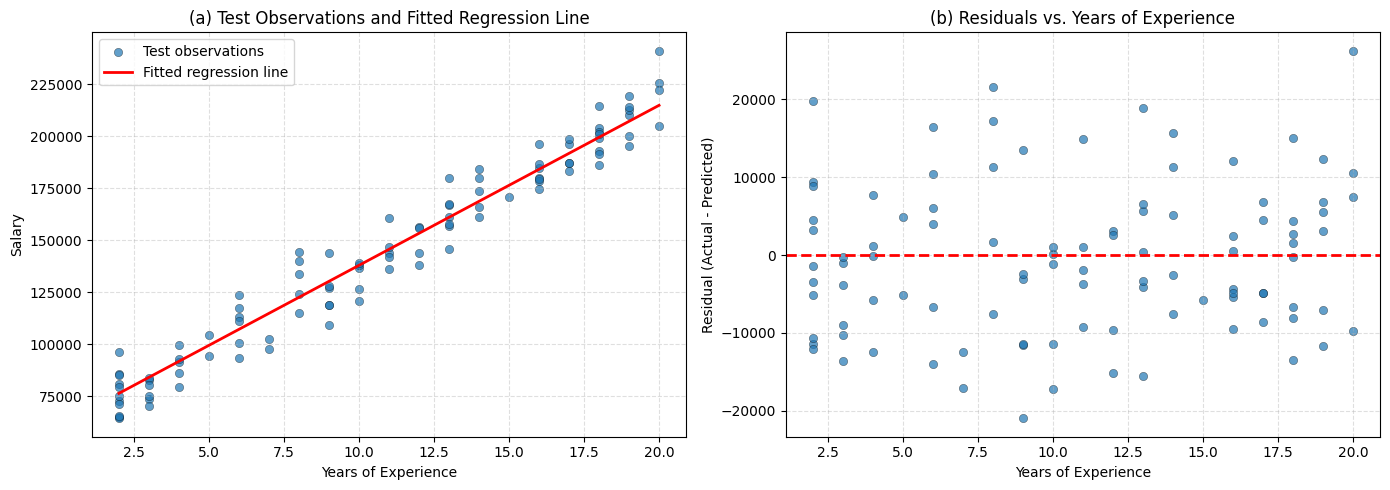

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})


X = df[["YearsOfExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
model = LinearRegression().fit(X_train, y_train)

y_pred = model.predict(X_test)
residuals = y_test.values - y_pred

x_line = np.linspace(X_test["YearsOfExperience"].min(),
                     X_test["YearsOfExperience"].max(), 100)
y_line = model.intercept_ + model.coef_[0] * x_line

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].scatter(X_test["YearsOfExperience"], y_test, alpha=0.7,
                edgecolor="k", linewidth=0.3, label="Test observations")
axes[0].plot(x_line, y_line, color="red", linewidth=2, label="Fitted regression line")
axes[0].set_xlabel("Years of Experience")
axes[0].set_ylabel("Salary")
axes[0].set_title("(a) Test Observations and Fitted Regression Line")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)


axes[1].scatter(X_test["YearsOfExperience"], residuals, alpha=0.7,
                edgecolor="k", linewidth=0.3)
axes[1].axhline(y=0, color="red", linestyle="--", linewidth=2)
axes[1].set_xlabel("Years of Experience")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("(b) Residuals vs. Years of Experience")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### Task 9. Predict new salaries

Use the linear regression model to predict salaries for **5, 10 and 15 years** of experience. Display the results in a table.

In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})


X = df[["YearsOfExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
model = LinearRegression().fit(X_train, y_train)

new_X = pd.DataFrame({"YearsOfExperience": [5, 10, 15]})
predicted_salary = model.predict(new_X)


results = pd.DataFrame({
    "YearsOfExperience": new_X["YearsOfExperience"],
    "Predicted Salary": predicted_salary.round(2)
})
print(results.to_string(index=False))

 YearsOfExperience  Predicted Salary
                 5          99444.41
                10         137927.47
                15         176410.53


### Task 10. Standardize the feature

Use `StandardScaler` on `X_train` and `X_test`. Fit the scaler on the training set only, then transform both sets. Keep the target `y` unchanged.

In [12]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})

X = df[["YearsOfExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaler mean (from train):", scaler.mean_)
print("Scaler std  (from train):", scaler.scale_)

print("\nX_train_scaled -> mean: %.4f, std: %.4f"
      % (X_train_scaled.mean(), X_train_scaled.std()))
print("X_test_scaled  -> mean: %.4f, std: %.4f"
      % (X_test_scaled.mean(), X_test_scaled.std()))

print("\nShapes:", X_train_scaled.shape, X_test_scaled.shape)
print("y unchanged (first 3 of y_train):")
print(y_train.head(3))

Scaler mean (from train): [10.575]
Scaler std  (from train): [5.61421188]

X_train_scaled -> mean: 0.0000, std: 1.0000
X_test_scaled  -> mean: 0.0365, std: 1.0373

Shapes: (400, 1) (100, 1)
y unchanged (first 3 of y_train):
249    182434.585064
433    108868.778635
19     145681.479563
Name: Salary, dtype: float64


### Task 11. Train Ridge regression

Fit two `Ridge` models on the scaled training set, using `alpha=10` and `alpha=100`. For each model, display its coefficient, test MAE and test R2. Compare the coefficients. Keep the `alpha=10` model for Task 13.

In [13]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})


X = df[["YearsOfExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


ols = LinearRegression().fit(X_train_scaled, y_train)


ridge_10 = Ridge(alpha=10).fit(X_train_scaled, y_train)
ridge_100 = Ridge(alpha=100).fit(X_train_scaled, y_train)


rows = []
for name, m in [("OLS (reference)", ols),
                ("Ridge alpha=10", ridge_10),
                ("Ridge alpha=100", ridge_100)]:
    pred = m.predict(X_test_scaled)
    rows.append({
        "Model": name,
        "Coefficient": m.coef_[0],
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("Model")
print(results.round(4))
print("\nShrinkage relative to OLS:")
print(f"alpha=10 : {ridge_10.coef_[0] / ols.coef_[0]:.4f}")
print(f"alpha=100: {ridge_100.coef_[0] / ols.coef_[0]:.4f}")


ridge_model = ridge_10

                 Coefficient    Test MAE  Test R2
Model                                            
OLS (reference)   43210.4157   7905.1147   0.9574
Ridge alpha=10    42156.5031   8084.4613   0.9557
Ridge alpha=100   34568.3325  11308.3700   0.9118

Shrinkage relative to OLS:
alpha=10 : 0.9756
alpha=100: 0.8000


### Task 12. Train Lasso regression

Fit three `Lasso` models on the scaled training set, using `alpha=1000`, `alpha=10000` and `alpha=50000`. Set `max_iter=20000`. For each model, display its coefficient, test MAE and test R2. Observe what happens to the coefficient as alpha increases. Keep the `alpha=1000` model for Task 13.

In [14]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})


X = df[["YearsOfExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


ols = LinearRegression().fit(X_train_scaled, y_train)

alphas = [1000, 10000, 50000]
lasso_models = {a: Lasso(alpha=a, max_iter=20000).fit(X_train_scaled, y_train)
                for a in alphas}


rows = [{
    "Model": "OLS (reference)",
    "Coefficient": ols.coef_[0],
    "Test MAE": mean_absolute_error(y_test, ols.predict(X_test_scaled)),
    "Test R2": r2_score(y_test, ols.predict(X_test_scaled)),
}]
for a, m in lasso_models.items():
    pred = m.predict(X_test_scaled)
    rows.append({
        "Model": f"Lasso alpha={a}",
        "Coefficient": m.coef_[0],
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test R2": r2_score(y_test, pred),
    })
results = pd.DataFrame(rows).set_index("Model")
print(results.round(4))

lasso_model = lasso_models[1000]

                   Coefficient    Test MAE  Test R2
Model                                              
OLS (reference)     43210.4157   7905.1147   0.9574
Lasso alpha=1000    42210.4157   8074.6515   0.9558
Lasso alpha=10000   33210.4157  12287.9627   0.8980
Lasso alpha=50000       0.0000  40444.9579  -0.0005


### Task 13. Compare the models

Create a table showing test MAE, RMSE and R2 for: the mean baseline, linear regression, Ridge (`alpha=10`) and Lasso (`alpha=1000`). Write two sentences about the results.

In [15]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


np.random.seed(42)
years_of_experience = np.random.randint(2, 21, size=500)
intercept = 60000
slope = (200000 - 60000) / (20 - 2)
noise = np.random.normal(0, 10000, size=500)
salary = intercept + slope * years_of_experience + noise
df = pd.DataFrame({"YearsOfExperience": years_of_experience, "Salary": salary})


X = df[["YearsOfExperience"]]
y = df["Salary"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


lin_model = LinearRegression().fit(X_train, y_train)
ridge_model = Ridge(alpha=10).fit(X_train_scaled, y_train)
lasso_model = Lasso(alpha=1000, max_iter=20000).fit(X_train_scaled, y_train)


predictions = {
    "Mean baseline":     np.full(len(y_test), y_train.mean()),
    "Linear regression": lin_model.predict(X_test),
    "Ridge (alpha=10)":  ridge_model.predict(X_test_scaled),
    "Lasso (alpha=1000)": lasso_model.predict(X_test_scaled),
}


rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "MAE":  mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2":   r2_score(y_test, pred),
    })
comparison = pd.DataFrame(rows).set_index("Model")
print(comparison.round(4))

                           MAE        RMSE      R2
Model                                             
Mean baseline       40444.9579  46953.7695 -0.0005
Linear regression    7905.1147   9691.9181  0.9574
Ridge (alpha=10)     8084.4613   9876.9316  0.9557
Lasso (alpha=1000)   8074.6515   9864.6082  0.9558


**Submission:** Save the notebook with your code, results and plots. Include your short comparison for Task 13.